**Box aspect** is the ratio between Axes height and Axes width in physical units, independent of data limits:

$$
Box \ Aspect = \frac{Axes \ height}{Axes \ width}
$$

#### A square Axes, independent of data

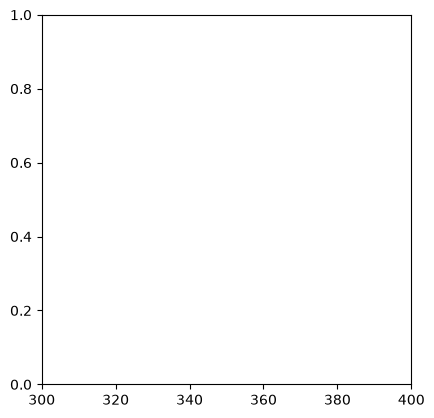

In [1]:
import matplotlib.pyplot as plt
import numpy as np

fig1, ax = plt.subplots()

ax.set_xlim(300, 400)
ax.set_box_aspect(1)

plt.show()

#### Shared square Axes

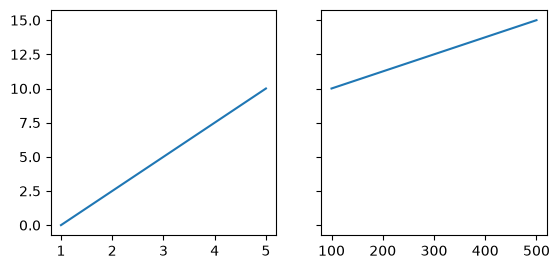

In [2]:
fig2, (ax, ax2) = plt.subplots(ncols=2, sharey=True)

ax.plot([1, 5], [0, 10])
ax2.plot([100, 500], [10, 15])

ax.set_box_aspect(1)
ax2.set_box_aspect(1)

plt.show()

#### Square twin Axes

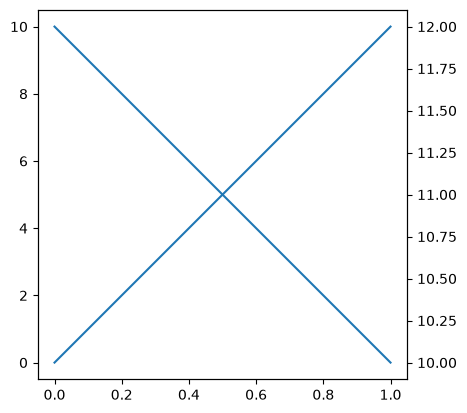

In [3]:
fig3, ax = plt.subplots()

ax2 = ax.twinx()

# Specify only the y-values
ax.plot([0, 10])
ax2.plot([12, 10])

ax.set_box_aspect(1)
plt.show()

#### Normal plot next to image

The normal plot's Axes, use the image's dimensions as box aspect.

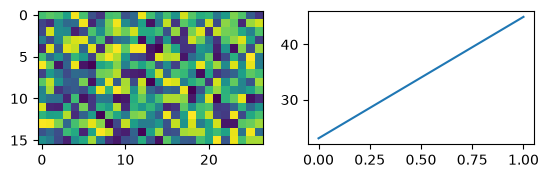

In [4]:
fig4, (ax, ax2) = plt.subplots(ncols=2)

np.random.seed(19680801)
im = np.random.rand(16, 27)
ax.imshow(im)

ax2.plot([23, 45])
ax2.set_box_aspect(im.shape[0] / im.shape[1])

plt.show()

#### Square joint/marginal plot

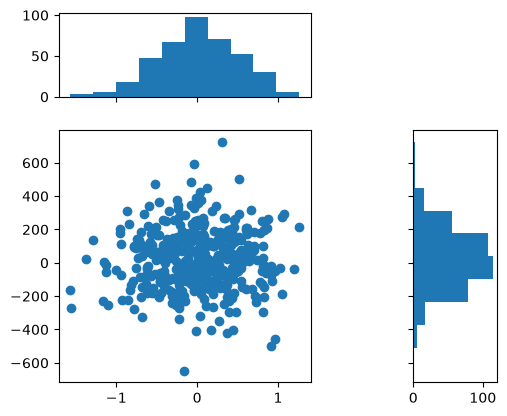

In [ ]:
fig5, axs = plt.subplots(
    2,
    2,
    sharex="col",
    sharey="row",
    gridspec_kw=dict(
        height_ratios=[1, 3],
        width_ratios=[3, 1],
    ),
)

# Hide the top right Axes
axs[0, 1].set_visible(False)
axs[0, 0].set_box_aspect(1 / 3)
axs[1, 0].set_box_aspect(1)
axs[1, 1].set_box_aspect(3 / 1)

np.random.seed(19680801)
x, y = np.random.randn(2, 400) * [[0.5], [180]]
axs[1, 0].scatter(x, y)
axs[0, 0].hist(x)
axs[1, 1].hist(y, orientation="horizontal")


plt.show()

#### Set data aspect with box aspect

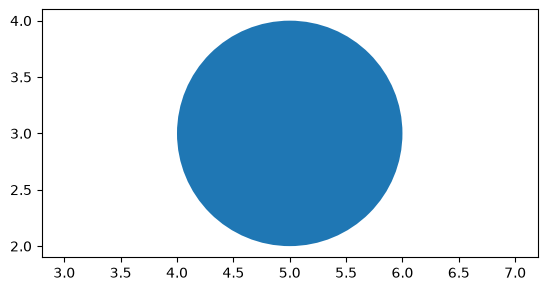

In [ ]:
fig6, ax = plt.subplots()

# A circle with center at (5, 3) and radius 1
ax.add_patch(plt.Circle((5, 3), 1))
# Set the aspect ratio of the Axes scaling i.e. y/x scale
# "equal" means same scaling for both x and y axes.
# adjustable controls which parameter will be adjusted to achieve the desired aspect ratio. Here, we choose to adjust the data limits.
ax.set_aspect("equal", adjustable="datalim")
# Set the Axes box to have a width twice its height
ax.set_box_aspect(0.5)
# Autoscale the axis view to fit the circle within the Axes.
ax.autoscale()

plt.show()

#### Box aspect for many subplots

A 2 by 3 subplot with all square Axes

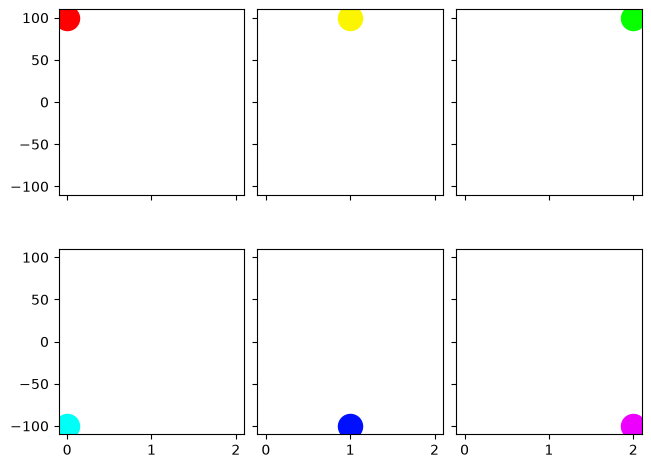

In [18]:
fig7, axs = plt.subplots(
    2,
    3,
    subplot_kw=dict(box_aspect=1),
    sharex=True,
    sharey=True,
    layout="constrained",
)

for i, ax in enumerate(axs.flat):
    ax.scatter(
        i % 3,
        -((i // 3) - 0.5) * 200,
        c=[plt.colormaps["hsv"](i / 6)],
        s=300,
    )